# 07 · Brain-region cropping, near-duplicate check and the leak-free split
**Owner:** shared (cropping: Mihika; near-duplicate check: Pihu; split + shortcut probes: Udita)

The interim report listed two risks for the final phase: an **image-source shortcut** (no-tumor scans come from a different source and have different file sizes and borders) and **near-duplicate slices** that exact (MD5) de-duplication cannot catch. This notebook fixes the first by cropping every slice to the head and measures the second.

In [1]:
%matplotlib inline
import os, sys
os.environ.setdefault("KERAS_BACKEND", "torch")   # Keras 3 backend used for our runs (CPU); "tensorflow" also works
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # make the project's src/ package importable

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from IPython.display import Image, display
from src import config, data_pipeline as dp, models, features, training

keras.utils.set_random_seed(config.SEED)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())
from src import experiments as E, evaluation as ev, finetune as F, gradcam as G
RERUN = False    # True = retrain everything here; False = load the saved runs produced by the same code
                 # (scripts/run_heads.py, scripts/run_finetune.py), which take hours on a CPU

Keras 3.15.1 | backend: torch


## 1. Crop every slice to the head, pad to square, resize to 256 × 256

In [2]:
from src import cropping
boxes_csv = config.DATASET_INFO_DIR / "crop_boxes.csv"
boxes = cropping.build_cropped_dataset() if (RERUN or not boxes_csv.exists()) else pd.read_csv(boxes_csv)
boxes.to_csv(boxes_csv, index=False)
print(len(boxes), "cropped images")

7013 cropped images


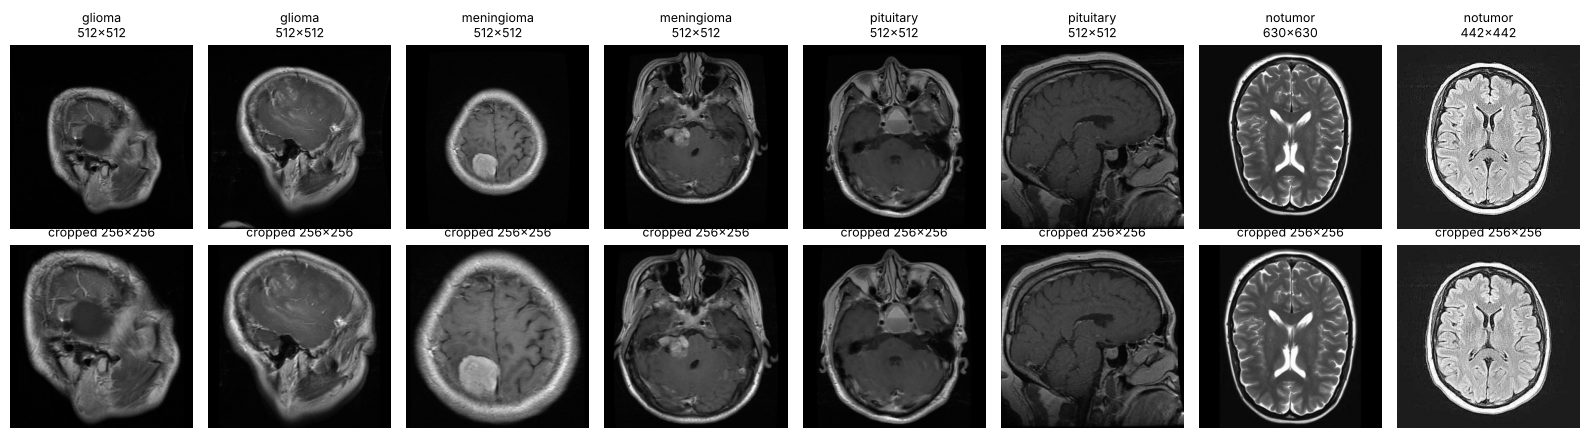

In [3]:
import cv2
sel = pd.concat([boxes[boxes.source_class == c].sample(2, random_state=3)
                 for c in ["glioma", "meningioma", "pituitary", "notumor"]])
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for k, r in enumerate(sel.itertuples()):
    ax[0, k].imshow(cv2.imread(str(config.ROOT / r.binary_path.replace("\\", "/")), 0), cmap="gray")
    ax[0, k].set_title(f"{r.source_class}\n{r.width}×{r.height}", fontsize=9)
    ax[1, k].imshow(cv2.imread(str(config.ROOT / r.cropped_path), 0), cmap="gray")
    ax[1, k].set_title("cropped 256×256", fontsize=9)
for a in ax.flat: a.axis("off")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "crop_examples.png", dpi=150); plt.show()

## 2. Near-duplicate check (perceptual hash + pixel correlation)
pHash (64-bit) of every cropped image under all 8 flips/rotations; pairs within 8 bits are candidates, and a candidate is confirmed when the 64 × 64 crops correlate ≥ 0.97 under the best flip/rotation. Visual checks (below) show confirmed pairs are the same slice re-saved, flipped, rescaled or with changed contrast.

In [4]:
from src import near_duplicates as nd
pairs_csv = config.DATASET_INFO_DIR / "near_duplicate_pairs.csv"
if RERUN or not pairs_csv.exists():
    H = nd.phash_table(boxes)
    pairs = nd.confirm_pairs(boxes, nd.find_pairs(H, max_bits=8))
    pairs.to_csv(pairs_csv, index=False)
pairs = pd.read_csv(pairs_csv)
summary = json.loads((config.DATASET_INFO_DIR / "near_duplicate_summary.json").read_text())
print(json.dumps({k: v for k, v in summary.items() if k != "final_split_counts"}, indent=1))

{
 "phash_candidate_pairs_le8bits": 33350,
 "confirmed_pairs_corr_ge_0.97": 13682,
 "groups": 3844,
 "images_with_a_near_duplicate": 5145,
 "largest_group": 78,
 "original_split_cross_pairs": 7756,
 "original_test_images_with_near_dup_in_train_or_val": 1087,
 "original_val_images_with_near_dup_in_train": 565,
 "final_class_weights": {
  "no_tumor": 2.0856,
  "tumor": 0.6577
 }
}


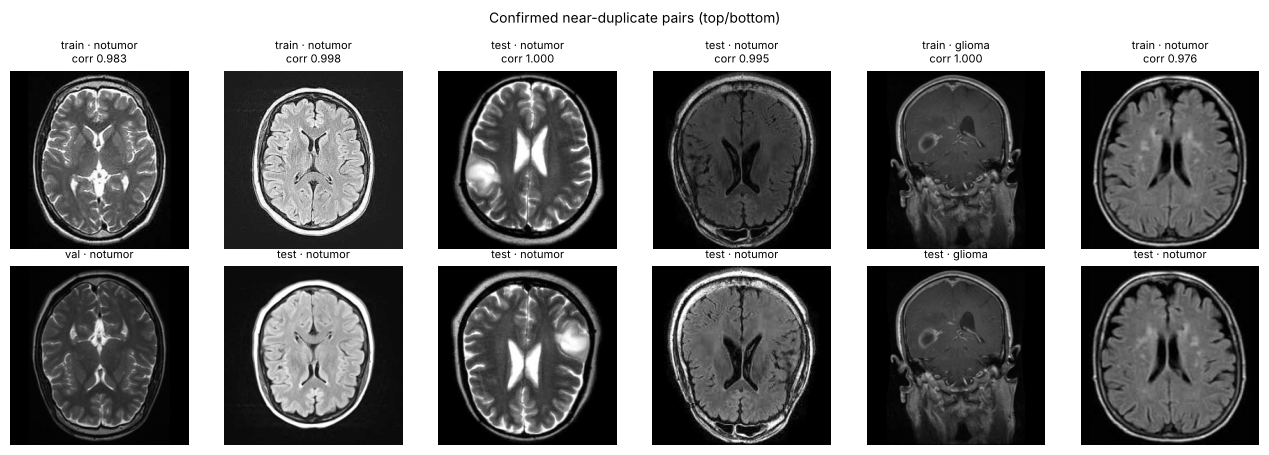

In [5]:
conf = pairs[pairs["corr"] >= nd.CORR_THRESHOLD].sample(6, random_state=0)
fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
for k, r in enumerate(conf.itertuples()):
    for row, i in enumerate([r.i, r.j]):
        b = boxes.iloc[i]
        ax[row, k].imshow(cv2.imread(str(config.ROOT / b.cropped_path), 0), cmap="gray")
        ax[row, k].set_title(f"{b.split} · {b.source_class}" + (f"\ncorr {r.corr:.3f}" if row == 0 else ""), fontsize=8)
for a in ax.flat: a.axis("off")
fig.suptitle("Confirmed near-duplicate pairs (top/bottom)", fontsize=10)
fig.tight_layout(); fig.savefig(config.FIG_DIR / "near_duplicate_examples.png", dpi=150); plt.show()

## 3. Leak-free split
Every near-duplicate group goes entirely to train, validation or test (`StratifiedGroupKFold`, 13 folds: 3 → test, 2 → validation, 8 → train, stratified by the 4 source classes, seed 42). This split is used by all four models in the final comparison.

In [6]:
final = pd.read_csv(config.DATASET_INFO_DIR / "split_manifest_final.csv")
assert (final.groupby("group").split.nunique() == 1).all()          # no group crosses splits
tab = pd.crosstab(final.split, final.label).reindex(["train", "val", "test"]); tab["total"] = tab.sum(axis=1)
tab["tumor_%"] = (100 * tab.tumor / tab.total).round(1); print(tab)
print("class weights (train):", E.class_weight(final))
orig_test = final[final.split_original == "test"]
print(f"original test images with a near-duplicate in original train/val: {orig_test.leaked_in_original_split.sum()} of {len(orig_test)}")
print(orig_test.groupby("source_class").leaked_in_original_split.mean().round(3))

label  no_tumor  tumor  total  tumor_%
split                                 
train      1034   3279   4313     76.0
val         258    822   1080     76.1
test        389   1231   1620     76.0
class weights (train): {0: 2.0855899419729207, 1: 0.6576700213479719}
original test images with a near-duplicate in original train/val: 1087 of 1584
source_class
glioma        0.303
meningioma    0.726
notumor       0.975
pituitary     0.728
Name: leaked_in_original_split, dtype: float64


## 4. Shortcut probes (no tumor-specific information)
* **Image-size rule:** tumor iff the original file is 512 × 512.
* **Histogram probe:** logistic regression on the 32-bin grey-level histogram of the *cropped* image — no spatial information, so it can only use overall contrast/brightness (scanner, MRI sequence, source).

In [7]:
probes = {}
for p in ["original_uncropped", "original_cropped", "final"]:
    m = E.manifest_for(p)
    probes[f"size rule · {p}"] = ev.size_rule(m, "test")
    col = "binary_path" if p == "original_uncropped" else "cropped_path"
    if p == "original_uncropped":
        m = m.assign(binary_path=m.binary_path.str.replace("\\", "/", regex=False))
    probes[f"histogram probe · {p}"] = ev.histogram_probe(m, path_col=col)
ev.save_json(probes, "shortcut_probes.json")
ev.metrics_table(probes)

,accuracy,precision,recall,specificity,f1,balanced_accuracy,roc_auc,FN,FP
model,,,,,,,,,
size rule · original_uncropped,0.8794,0.9970,0.8412,0.9925,0.9125,0.9169,0.9169,188,3
histogram probe · original_uncropped,0.8504,0.9143,0.8826,0.7550,0.8982,0.8188,0.8925,139,98
size rule · original_cropped,0.8794,0.9970,0.8412,0.9925,0.9125,0.9169,0.9169,188,3
histogram probe · original_cropped,0.8554,0.9313,0.8708,0.8100,0.9000,0.8404,0.9123,153,76
size rule · final,0.9475,1.0000,0.9310,1.0000,0.9642,0.9655,0.9655,85,0
histogram probe · final,0.8685,0.9152,0.9115,0.7326,0.9133,0.8221,0.8877,109,104


**Reading:** the size rule is defeated by cropping only in the sense that the models never see the file size; the histogram probe shows that the *contrast* of no-tumor scans (mostly T2-weighted, from Br35H) still differs from tumor scans (mostly contrast-enhanced T1, from Figshare). Cropping cannot remove that; it is a property of how the public dataset was assembled, and it is discussed as a limitation in the report.